# Lab 1-02：模型其實只做一件事——猜下一個 token

**目標**：用 `transformers` 打開一個真的小模型，印出它對「下一個 token」的機率分布；
再用 `model.generate()` 調溫度、top-p，看參數怎麼改變輸出；最後畫出真實模型的 attention 熱圖。

**你會學到**
- 語言模型是一個「詞表大小」的分類器，輸出是 logits → softmax 機率
- 生成一段話＝把「猜下一個」放進迴圈，`generate()` 幫你跑這個迴圈
- 溫度與 top-p 只是在改抽樣方式
- attention 權重長什麼樣：每個 token 回頭看前面的誰
- 幻覺從哪裡來

**前置**：先讀 `00_concepts.md` 第 2～4 節。會下載 `Qwen/Qwen2.5-0.5B`（約 1GB）。有 GPU 最好，CPU 也跑得動，只是慢一點。

**對應投影片**：「embedding 就是查表」「語言模型是詞表分類器」「逐字生成是個迴圈」「溫度只管隨機性」「attention 直覺」「幻覺從哪來」

![生成迴圈：已有的 token 進 LLM，得到詞表機率分布，抽樣出下一個 token，再接回去](images/generation_loop.jpg)

*圖：生成一段話就是這個迴圈。模型本身只負責「算機率」那一格；溫度和 top-p 只動「抽樣」那一格。*

## Step 1：載入模型

這裡用的是**基礎模型**（base model），只做過預訓練、沒教過對話，最適合看「猜下一個字」的原始行為。
`attn_implementation="eager"` 讓模型能把 attention 權重交出來（Step 6 會用到）。

In [1]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_grad_enabled(False)  # 這本只做推論，不需要算梯度

tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32, attn_implementation="eager").to(device).eval()

cfg = model.config
print(f"參數量：{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M，詞表大小：{len(tok)}，裝置：{device}")
print(f"{cfg.num_hidden_layers} 層，每個 token 的向量寬 {cfg.hidden_size}，{cfg.num_attention_heads} 個 attention 頭")

參數量：494M，詞表大小：151665，裝置：cuda
24 層，每個 token 的向量寬 896，14 個 attention 頭


## Step 2：輸出是「詞表裡每個 token 的分數」

文字先切成 token id（上一本），模型跑一次前向傳播，每個位置都得到一個長度＝詞表大小的向量（logits）。
我們只關心最後一個位置：它就是「下一個 token 是誰」的分數。套上 softmax 就是機率。

In [2]:
prompt = "魯夫想成為"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
print("輸入的 token：", [tok.decode(i) for i in ids[0]])

logits = model(ids).logits
print("logits 形狀：", tuple(logits.shape), "（批次 × 序列長度 × 詞表大小）")

probs = torch.softmax(logits[0, -1], dim=-1)
top = torch.topk(probs, 10)
for p, i in zip(top.values, top.indices):
    print(f"{p.item():6.1%}  {tok.decode(i)!r}")

輸入的 token： ['魯', '夫', '想', '成為']
logits 形狀： (1, 4, 151936) （批次 × 序列長度 × 詞表大小）
 16.6%  '一個'
  9.3%  '一名'
  4.5%  '一位'
  1.5%  '哪'
  1.5%  '什麼'
  1.4%  '世界'
  1.4%  '醫生'
  1.2%  '足球'
  1.0%  '一家'
  0.9%  '一'


這跟影像分類的最後一層是同一件事，只是類別有十幾萬個。模型沒有「理解句子再回答」的步驟，只有一個分類器在打分數。

## Step 3：生成＝把「猜下一個」放進迴圈

下面這 5 行就是生成的全部：每次挑機率最高的（greedy），接到後面，再猜一次。

In [3]:
x = ids
for _ in range(15):
    next_id = model(x).logits[0, -1].argmax().view(1, 1)
    x = torch.cat([x, next_id], dim=1)
print(tok.decode(x[0]))

魯夫想成為一個成功的商人，他需要在哪些方面進行投資？
作為一個成功的


實務上不用自己寫：`model.generate()` 就是這個迴圈，還幫你處理了停止條件、快取（不用每次從頭算）和各種抽樣方式。
`do_sample=False` 就是 greedy，結果應該跟上面一模一樣。

In [4]:
out = model.generate(ids, max_new_tokens=15, do_sample=False)
print(tok.decode(out[0]))

魯夫想成為一個成功的商人，他需要在哪些方面進行投資？
作為一個成功的


投影片上的「Agent＝模型＋迴圈」，最底層也是這個迴圈。

## Step 4：溫度——把分布壓扁或拉尖

抽樣前把 logits 除以溫度 T：T 小，高分的更突出（穩定）；T 大，分布被壓平（隨機）。
拿 Step 2 那組 logits，畫三種溫度下的前 10 名機率。

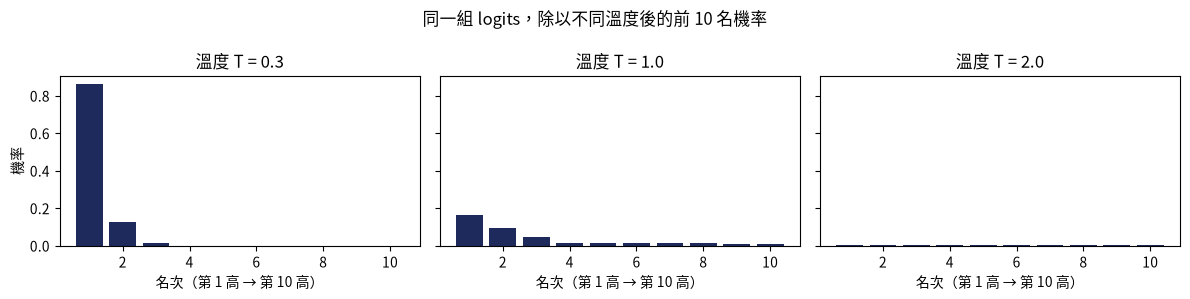

In [5]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()
last = logits[0, -1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, T in zip(axes, [0.3, 1.0, 2.0]):
    p = torch.softmax(last / T, dim=-1)
    ax.bar(range(1, 11), torch.topk(p, 10).values.cpu(), color="#1f2a5c")
    ax.set_title(f"溫度 T = {T}")
    ax.set_xlabel("名次（第 1 高 → 第 10 高）")
axes[0].set_ylabel("機率")
fig.suptitle("同一組 logits，除以不同溫度後的前 10 名機率")
plt.tight_layout()
plt.show()

用 `generate()` 實際抽三次看看。`do_sample=True` 才會抽樣；`num_return_sequences=3` 一次生三條。

In [6]:
def sample(prompt: str, temperature: float, top_p: float = 1.0, n: int = 3) -> list[str]:
    ids = tok(prompt, return_tensors="pt").input_ids.to(device)
    out = model.generate(ids, max_new_tokens=20, do_sample=True, temperature=temperature, top_p=top_p,
                         num_return_sequences=n, pad_token_id=tok.eos_token_id)
    return [tok.decode(o[ids.shape[1]:], skip_special_tokens=True) for o in out]


torch.manual_seed(0)
for T in [0.3, 1.5]:
    print(f"--- T = {T}")
    for s in sample("魯夫想成為", temperature=T):
        print("魯夫想成為" + s.replace("\n", " "))

--- T = 0.3
魯夫想成為一個成功的商人，他需要花費多少時間才能成為一個成功的商人？ 要成為一個成功的
魯夫想成為一名足球明星。他每週踢10場比賽，每場比賽需要150
魯夫想成為一個成功的商人。他開始研究商業模式和市場趨勢，並與一些志同
--- T = 1.5
魯夫想成為自己的親父並娶給她——他的祖祖父——的女朋友。他已經是39
魯夫想成為一個很棒足球 players.足球比賽後,在球東中尋找他想稱道的
魯夫想成為第一台飛上五週之間飛行的蝙蝠，於是他向一位飛行教授


T = 1.5 時冷門 token 也常被抽中，句子很快變得語無倫次，甚至混進別的語言。
溫度不會讓模型變聰明或變笨，它只決定「要不要常挑第二、第三名」。要精準輸出（JSON、SQL、程式碼）時用低溫；要發想時才調高。

## Step 5：top-p——把長尾整段剪掉

top-p 只保留「機率由高到低累加到 p 為止」的那些 token，其餘一律不抽。
先看 Step 2 那組分布：p 設成不同值時，各會留下幾個候選。

In [7]:
sorted_p = torch.sort(probs, descending=True).values
cum = torch.cumsum(sorted_p, dim=0)
for p in [0.5, 0.9, 0.99]:
    print(f"top_p = {p}：留下 {(cum < p).sum().item() + 1} 個候選 token（詞表共 {len(tok)} 個）")

top_p = 0.5：留下 37 個候選 token（詞表共 151665 個）
top_p = 0.9：留下 1450 個候選 token（詞表共 151665 個）
top_p = 0.99：留下 13044 個候選 token（詞表共 151665 個）


In [8]:
torch.manual_seed(0)
for top_p in [1.0, 0.5]:
    print(f"--- T = 1.5，top_p = {top_p}")
    for s in sample("魯夫想成為", temperature=1.5, top_p=top_p):
        print("魯夫想成為" + s.replace("\n", " "))

--- T = 1.5，top_p = 1.0
魯夫想成為國家隊中最重要的個案，他不僅希望國家隊在歐州級體能競賽
魯夫想成為醫生？說：A 魯夫的醫生生涯很順利啊！  現在魯夫打算
魯夫想成為哪一類戰士？他需要從哪裡獲得所需的知識？這對他的使命又是什么呢
--- T = 1.5，top_p = 0.5
魯夫想成為一位出色的戰士。他開始學習如何打拳，因為他的父母都在學這門藝術
魯夫想成為一個好戰的武術高手。她需要學習一些新的技能。她的父母為她提供
魯夫想成為一個有經驗的足球隊長，他必須從24人隊中選選隊長


同樣是高溫，top_p = 0.5 把長尾剪掉後，句子明顯比較收斂。實務上溫度和 top-p 通常只調一個。

## Step 6：attention——每個 token 回頭看誰

模型中間那一大段 Transformer 在做的事，最核心的是 attention：每個 token 回頭看前面所有 token，決定要從誰身上拿多少資訊（原理見 `00_concepts.md` 第 4 節）。
加上 `output_attentions=True`，模型會把每一層、每個頭的權重表交出來。

In [9]:
sentence = "魯夫吃了橡膠果實，所以他的身體可以伸長"
sid = tok(sentence, return_tensors="pt").input_ids.to(device)
att = model(sid, output_attentions=True).attentions

labels = [tok.decode(i) for i in sid[0]]
print(f"共 {len(att)} 層；每層形狀 {tuple(att[0].shape)}（批次 × 頭數 × N × N），N = {len(labels)} 個 token")

共 24 層；每層形狀 (1, 14, 14, 14)（批次 × 頭數 × N × N），N = 14 個 token


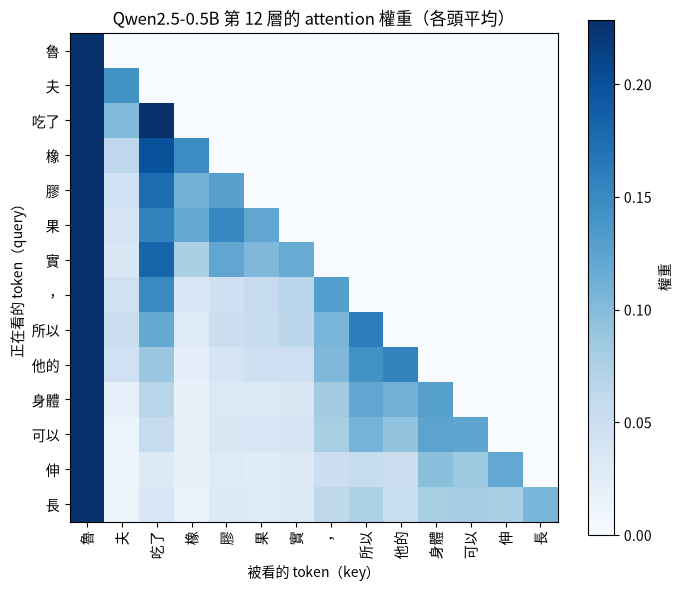

「他的」這一列（它把注意力分給誰），前 4 名：
  '魯'      0.311
  '他的'     0.155
  '所以'     0.142
  '，'      0.103


In [10]:
layer = 12
w = att[layer][0].mean(dim=0).cpu()  # 這一層所有頭取平均
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(w, cmap="Blues", vmax=w[1:, 1:].max())  # 第一個 token 常吸走大量權重，色階排除它才看得清楚
ax.set_xticks(range(len(labels)), labels, rotation=90)
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("被看的 token（key）")
ax.set_ylabel("正在看的 token（query）")
ax.set_title(f"Qwen2.5-0.5B 第 {layer} 層的 attention 權重（各頭平均）")
plt.colorbar(im, label="權重")
plt.tight_layout()
plt.show()

row = w[labels.index("他的")]
print("「他的」這一列（它把注意力分給誰），前 4 名：")
for j in row.topk(4).indices.tolist():
    print(f"  {labels[j]!r:8s} {row[j]:.3f}")

讀圖的方式：
- 每一列是一個 token「把注意力分給誰」，每一列加起來是 1。
- 右上半部全白：**因果遮罩**讓 token 只能看前面，這樣模型才能一個字一個字生成。
- 第一欄（「魯」）整條都很深：幾乎每個 token 都把大量注意力放在第一個 token 上。這是常見現象（attention sink），模型拿它當「沒什麼要看的時候」的預設去處。
- 所以「他的」這一列第一名是「魯」，不能直接解讀成「模型知道『他』指魯夫」：那也是 sink 的位置。單看一層、各頭平均的 attention 很容易過度解讀，研究上要看個別的頭、做對照實驗。
- 這張表是 N × N：句子長 2 倍，表就大 4 倍。context 越長越貴，就是從這裡來的。

## Step 7：幻覺從哪來

模型每一步都**一定**會輸出一個機率分布，結構上沒有「我不知道」這個選項。
問它一件語料裡不存在的事，它照樣會接出一段很順的話。

In [11]:
q = tok("台灣第一位登上月球的太空人是", return_tensors="pt").input_ids.to(device)
print(tok.decode(model.generate(q, max_new_tokens=30, do_sample=False)[0]))

台灣第一位登上月球的太空人是？
A. 郭守敬
B. 王亚平
C. 翟志刚
D. 刘洋


從來沒有台灣人登上月球，但模型照樣接了下去：接出一份很像考題的選擇題，選項還是真實存在的人名。
它沒有查證，只是在模仿預訓練語料裡的句型：內容是「最像下一句」的東西，不保證是真的。
後面的 RAG（模組 3）就是在解決這件事：先把相關資料找出來塞進 prompt，讓它照著資料回答。

## 試試看

1. 把 Step 2 的 prompt 換成英文 `"Luffy wants to become"`，比較前 10 名。
2. 把 Step 6 的 `layer` 改成 0 和 23，attention 熱圖有什麼不同？
3. 把 `MODEL` 換成對話版 `Qwen/Qwen2.5-0.5B-Instruct`，Step 7 的回答有變嗎？為什麼還是可能亂講？

## 小結

- 模型最後一層是「詞表大小」的分類器；生成＝猜下一個 token 的迴圈，`generate()` 幫你跑。
- 溫度和 top-p 只改抽樣方式；attention 是 N × N 的權重表，context 越長越貴。
- 模型永遠會給答案，所以會幻覺。下一本：不碰模型內部，直接用 OpenAI SDK 跟模型對話。